# Food-11 image classification

These experiments compare pretrained vision models and test-time augmentation on Food-11. Place the dataset under `food11/train` and `food11/test`; install PyTorch, torchvision, Pillow, TensorBoard, NumPy, Matplotlib, seaborn, scikit-learn and tqdm. The first run downloads pretrained weights. Some experiments previously took more than an hour.

Unreadable and very small images are excluded without deleting files. Test-time augmentation averages the original image and a horizontal flip. The training outputs are historical and predate these code corrections. The final section evaluates a saved EfficientNet-B0 checkpoint with the updated data handling. Multiple models were compared against the same test set, so those test results are exploratory rather than a final independent selection estimate.

The training cells reload checkpoints created by this notebook with `weights_only=False`; use only checkpoints you trust.

**Data:** [Food image collection with 11 classes](https://github.com/InsiyaFakhruddin/Food_Classifier/tree/main/food11). Its 11,000 images match the local files used in this lesson. Place the `train/` and `test/` folders under `food11/`.

## Earlier experiment results

These figures come from the original runs, before the image validation and test-time augmentation changes above. They are retained for context and should not be presented as results of the updated code. All models were compared on the same test set.

| Model | Validation accuracy | Test accuracy | Earlier TTA accuracy | Training time |
|---|---:|---:|---:|---:|
| EfficientNet-B0 | 78.38% | 76.45% | — | 44.2 min |
| EfficientNet-B0 fine-tuned | 81.87% | 79.00% | 82.09% | 74.3 min |
| EfficientNet-B3 fine-tuned | 84.34% | 82.00% | 84.82% | 119.9 min |
| ConvNeXt V2 fine-tuned | 88.38% | 88.55% | 89.18% | 158.1 min |
| DaViT Tiny fine-tuned | 92.88% | 92.64% | 92.82% | 616.7 min |

Saved figures: [B0](images/B0.png), [fine-tuned B0](images/B0_finetune.png), [B3](images/B3.png), [ConvNeXt V2](images/ConvNeXt_V2.png).

In [ ]:
from PIL import Image

def valid_image(path):
    """Keep readable images of at least 50×50 pixels without modifying files."""
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            image.load()
            return min(image.size) >= 50
    except (OSError, ValueError):
        return False


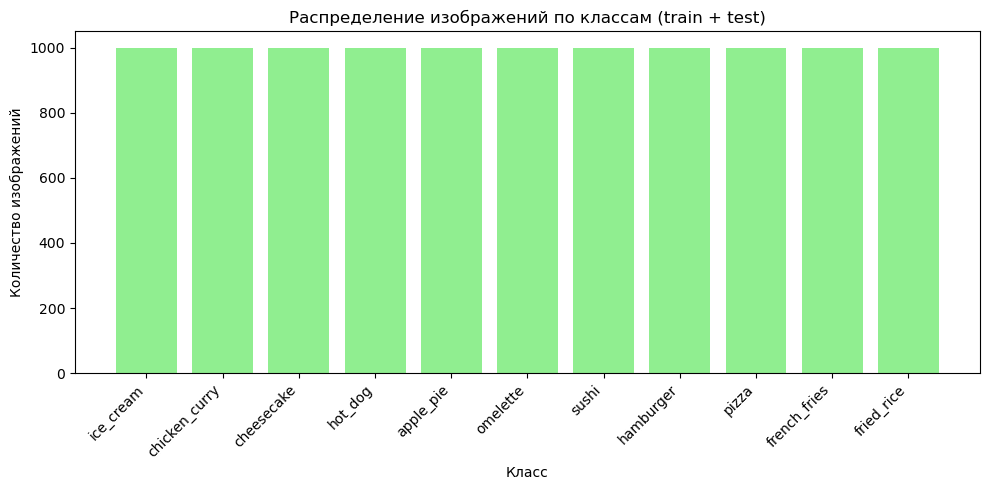

In [10]:
from collections import Counter
import matplotlib.pyplot as plt
import os

def plot_total_distribution(root_dir='food11'):
    total_counts = Counter()

    for split in ['train', 'test']:
        split_dir = os.path.join(root_dir, split)
        for class_name in os.listdir(split_dir):
            class_path = os.path.join(split_dir, class_name)
            if not os.path.isdir(class_path):
                continue
            n = len(os.listdir(class_path))
            total_counts[class_name] += n

    plt.figure(figsize=(10,5))
    plt.bar(total_counts.keys(), total_counts.values(), color='lightgreen')
    plt.title("Распределение изображений по классам (train + test)")
    plt.xlabel("Класс")
    plt.ylabel("Количество изображений")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

plot_total_distribution("food11")


In [12]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from torch.utils.data import Subset


data_dir = "food11"
train_dir = os.path.join(data_dir, "train")
test_dir = os.path.join(data_dir, "test")

batch_size = 32
num_epochs = 30
learning_rate = 1e-3

# Early stopping
patience = 5
best_acc = -float("inf")
patience_counter = 0

torch.manual_seed(42)
device = ("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

full_train_augmented = datasets.ImageFolder(train_dir, transform=train_transform, is_valid_file=valid_image)
full_train_clean = datasets.ImageFolder(train_dir, transform=val_test_transform, is_valid_file=valid_image)
test_dataset = datasets.ImageFolder(test_dir, transform=val_test_transform, is_valid_file=valid_image)
if full_train_augmented.class_to_idx != test_dataset.class_to_idx:
    raise ValueError("Train and test folders must contain the same classes.")

# Split на train/val (80/20)
train_size = int(0.8 * len(full_train_augmented))
val_size = len(full_train_augmented) - train_size

# Генерируем индексы для split
indices = list(range(len(full_train_augmented)))
np.random.seed(42)  # Для воспроизводимости
np.random.shuffle(indices)
train_indices = indices[:train_size]
val_indices = indices[train_size:]

# Создаём датасеты с правильными трансформациями
train_dataset = Subset(full_train_augmented, train_indices)
val_dataset = Subset(full_train_clean, val_indices)

num_classes = len(full_train_augmented.classes)
class_names = full_train_augmented.classes
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")
print(f"Классы ({num_classes}): {class_names}")

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

# Заморозка
for param in model.features.parameters():
    param.requires_grad = False

# Заменяем классификатор
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=learning_rate)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

writer = SummaryWriter(log_dir="runs/food11_efficientnet_B0")

def plot_confusion_matrix(cm, class_names, epoch):
    fig, ax = plt.subplots(figsize=(10, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Confusion Matrix - Epoch {epoch+1}')
    return fig

# Функция для оценки модели с мультиклассовыми метриками
def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = running_loss / len(loader)
    accuracy = 100.0 * np.mean(np.array(all_preds) == np.array(all_labels))
    precision = precision_score(all_labels, all_preds, average='macro')
    recall = recall_score(all_labels, all_preds, average='macro')
    f1 = f1_score(all_labels, all_preds, average='macro')
    cm = confusion_matrix(all_labels, all_preds)

    return avg_loss, accuracy, precision, recall, f1, all_preds, all_labels, cm


# Обучение
start_time = time.time()
print("\nОбучение (только классификатор)")

for epoch in range(num_epochs):
    epoch_start = time.time()
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]", leave=False, ncols=100)

    for images, labels in train_pbar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

        train_pbar.set_postfix({'loss': f'{loss.item():.3f}'})

    avg_train_loss = running_loss / len(train_loader)
    train_acc = 100. * correct / total

    # Валидация
    val_loss, val_acc, val_prec, val_rec, val_f1, val_preds, val_labels, val_cm = evaluate_model(model, val_loader, criterion, device)

    # Логи в TensorBoard
    writer.add_scalar("Loss/Train", avg_train_loss, epoch)
    writer.add_scalar("Loss/Validation", val_loss, epoch)
    writer.add_scalar("Accuracy/Train", train_acc, epoch)
    writer.add_scalar("Accuracy/Validation", val_acc, epoch)
    writer.add_scalar("Precision/Validation", val_prec, epoch)
    writer.add_scalar("Recall/Validation", val_rec, epoch)
    writer.add_scalar("F1/Validation", val_f1, epoch)
    writer.add_scalar("Learning_Rate", optimizer.param_groups[0]['lr'], epoch)

    if (epoch + 1) % 5 == 0:
        cm = confusion_matrix(val_labels, val_preds)
        cm_fig = plot_confusion_matrix(cm, class_names, epoch)
        writer.add_figure("Confusion_Matrix/Validation", cm_fig, epoch)
        plt.close(cm_fig)

    scheduler.step(val_acc)

    epoch_time = time.time() - epoch_start
    elapsed = time.time() - start_time
    est_remaining = (elapsed / (epoch + 1)) * (num_epochs - (epoch + 1))

    print(f"Epoch {epoch+1:02d}/{num_epochs} | "
          f"Train: L={avg_train_loss:.3f} A={train_acc:.1f}% | "
          f"Val: L={val_loss:.3f} A={val_acc:.1f}% | "
          f"LR={optimizer.param_groups[0]['lr']:.2e} | "
          f"Time: {epoch_time:.0f}s | ETA: {est_remaining/60:.1f}min")

    # Early stopping и сохранен е мождели
    if val_acc > best_acc:
        best_acc = val_acc
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_acc': best_acc,
            'class_names': class_names
        }, "best_efficientnet_B0_food11.pth")
        print(f"Лучшая модель сохранена! Val Acc: {best_acc:.2f}%")
    else:
        patience_counter += 1
        print(f"Нет улучшения {patience_counter}/{patience} эпох")

        if patience_counter >= patience:
            print(f"\nОстановка на эпохе {epoch+1}")
            print(f"Лучший результат: {best_acc:.2f}%")
            break

print("Финальная оценка на Test Set...")
checkpoint = torch.load("best_efficientnet_B0_food11.pth", map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])

test_loss, test_acc, test_prec, test_rec, test_f1, test_preds, test_labels, test_cm = evaluate_model(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.3f} | Accuracy: {test_acc:.2f}% | Precision: {test_prec:.3f} | Recall: {test_rec:.3f} | F1: {test_f1:.3f}")

total_time = time.time() - start_time
print(f"Общее время: {total_time/60:.1f} минут")
print(f"Лучшая Val Accuracy: {best_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Модель сохранена: best_efficientnet_B0_food11.pth")

writer.close()

Устройство: mps
Train: 7920 | Val: 1980 | Test: 1100
Классы (11): ['apple_pie', 'cheesecake', 'chicken_curry', 'french_fries', 'fried_rice', 'hamburger', 'hot_dog', 'ice_cream', 'omelette', 'pizza', 'sushi']


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to ~/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100.0%
/opt/miniconda3/envs/torch_ml/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(



Обучение (только классификатор)


Epoch 01/30 | Train: L=1.548 A=54.4% | Val: L=1.006 A=72.7% | LR=1.00e-03 | Time: 153s | ETA: 73.8min
Лучшая модель сохранена! Val Acc: 72.73%


Epoch 02/30 | Train: L=1.133 A=64.7% | Val: L=0.855 A=74.7% | LR=1.00e-03 | Time: 162s | ETA: 73.5min
Лучшая модель сохранена! Val Acc: 74.70%


Epoch 03/30 | Train: L=1.042 A=67.1% | Val: L=0.805 A=76.8% | LR=1.00e-03 | Time: 165s | ETA: 71.9min
Лучшая модель сохранена! Val Acc: 76.82%


... (13 outputs left out)

Epoch 17/30 | Train: L=0.860 A=72.5% | Val: L=0.708 A=78.1% | LR=5.00e-04 | Time: 149s | ETA: 33.6min
Нет улучшения 5/5 эпох

Остановка на эпохе 17
Лучший результат: 78.38%
Финальная оценка на Test Set...


/var/folders/pp/nnh10rws3jl0kc34jz4381080000gn/T/ipykernel_41469/913048568.py:215: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("best_efficientnet_B

Test Loss: 0.755 | Accuracy: 76.45% | Precision: 0.769 | Recall: 0.765 | F1: 0.764
Confusion matrix сохранена: confusion_matrix_test.png
Общее время: 44.2 минут
Лучшая Val Accuracy: 78.38%
Test Accuracy: 76.45%
Модель сохранена: best_efficientnet_B0_food11.pth


<Figure size 640x480 with 0 Axes>

In [15]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, WeightedRandomSampler
from torchvision import datasets, transforms, models
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from torch.utils.data import Subset
from collections import Counter

data_dir = "food11"
train_dir = os.path.join(data_dir, "train")
test_dir = os.path.join(data_dir, "test")

batch_size = 32
num_epochs = 50  # Увеличили — будем дообучать глубже
learning_rate_classifier = 1e-3
learning_rate_features = 1e-5  # Меньше для размороженных слоёв

patience = 7  # Больше терпения при fine-tuning
best_acc = -float("inf")
patience_counter = 0

torch.manual_seed(42)
device = ("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

full_train_augmented = datasets.ImageFolder(train_dir, transform=train_transform, is_valid_file=valid_image)
full_train_clean = datasets.ImageFolder(train_dir, transform=val_test_transform, is_valid_file=valid_image)
test_dataset = datasets.ImageFolder(test_dir, transform=val_test_transform, is_valid_file=valid_image)
if full_train_augmented.class_to_idx != test_dataset.class_to_idx:
    raise ValueError("Train and test folders must contain the same classes.")

# Split на train/val (80/20)
train_size = int(0.8 * len(full_train_augmented))
val_size = len(full_train_augmented) - train_size

indices = list(range(len(full_train_augmented)))
np.random.seed(42)
np.random.shuffle(indices)
train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = Subset(full_train_augmented, train_indices)
val_dataset = Subset(full_train_clean, val_indices)

num_classes = len(full_train_augmented.classes)
class_names = full_train_augmented.classes
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")
print(f"Классы ({num_classes}): {class_names}")

# Получаем метки из train_dataset
train_labels = [label for _, label in train_dataset]
class_counts = Counter(train_labels)
print("Распределение классов в train:", class_counts)

# Вычисляем веса для каждого класса
class_weights = [len(train_labels) / (num_classes * class_counts[i]) for i in range(num_classes)]
sample_weights = [class_weights[label] for label in train_labels]

# WeightedRandomSampler
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# Обновлённый train_loader с семплированием
train_loader = DataLoader(train_dataset, batch_size=batch_size, sampler=sampler, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, num_classes)

for name, param in model.named_parameters():
    if "features.7" in name or "features.8" in name or "classifier" in name:
        param.requires_grad = True
    else:
        param.requires_grad = False


print("\nОбучаемые параметры:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"  [Train] {name}")

model = model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1, weight=torch.tensor(class_weights).to(device))
print(f"Label Smoothing: 0.1 | Class weights: {class_weights}")

optimizer = optim.Adam([
    {'params': model.features.parameters(), 'lr': learning_rate_features},
    {'params': model.classifier.parameters(), 'lr': learning_rate_classifier}
])

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=4
)

writer = SummaryWriter(log_dir="runs/food11_efficientnet_B0_finetune")

def plot_confusion_matrix(cm, class_names, epoch):
    fig, ax = plt.subplots(figsize=(10, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Confusion Matrix - Epoch {epoch+1}')
    return fig

def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = running_loss / len(loader)
    accuracy = 100.0 * np.mean(np.array(all_preds) == np.array(all_labels))
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    cm = confusion_matrix(all_labels, all_preds)

    return avg_loss, accuracy, precision, recall, f1, all_preds, all_labels, cm

start_time = time.time()
print("\nОбучение (fine-tuning + label smoothing + weighted sampling)")

for epoch in range(num_epochs):
    epoch_start = time.time()
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]", leave=False, ncols=100)

    for images, labels in train_pbar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

        train_pbar.set_postfix({'loss': f'{loss.item():.3f}'})

    avg_train_loss = running_loss / len(train_loader)
    train_acc = 100. * correct / total

    # Валидация
    val_loss, val_acc, val_prec, val_rec, val_f1, val_preds, val_labels, val_cm = evaluate_model(model, val_loader, criterion, device)

    # Логи
    writer.add_scalar("Loss/Train", avg_train_loss, epoch)
    writer.add_scalar("Loss/Validation", val_loss, epoch)
    writer.add_scalar("Accuracy/Train", train_acc, epoch)
    writer.add_scalar("Accuracy/Validation", val_acc, epoch)
    writer.add_scalar("Precision/Validation", val_prec, epoch)
    writer.add_scalar("Recall/Validation", val_rec, epoch)
    writer.add_scalar("F1/Validation", val_f1, epoch)
    writer.add_scalar("Learning_Rate_Classifier", optimizer.param_groups[1]['lr'], epoch)
    writer.add_scalar("Learning_Rate_Features", optimizer.param_groups[0]['lr'], epoch)

    if (epoch + 1) % 5 == 0:
        cm_fig = plot_confusion_matrix(val_cm, class_names, epoch)
        writer.add_figure("Confusion_Matrix/Validation", cm_fig, epoch)
        plt.close(cm_fig)

    scheduler.step(val_acc)

    epoch_time = time.time() - epoch_start
    elapsed = time.time() - start_time
    est_remaining = (elapsed / (epoch + 1)) * (num_epochs - (epoch + 1))

    print(f"Epoch {epoch+1:02d}/{num_epochs} | "
          f"Train: L={avg_train_loss:.3f} A={train_acc:.1f}% | "
          f"Val: L={val_loss:.3f} A={val_acc:.1f}% | "
          f"LR_c={optimizer.param_groups[1]['lr']:.2e} LR_f={optimizer.param_groups[0]['lr']:.2e} | "
          f"Time: {epoch_time:.0f}s | ETA: {est_remaining/60:.1f}min")

    # Early stopping
    if val_acc > best_acc:
        best_acc = val_acc
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_acc': best_acc,
            'class_names': class_names
        }, "upgrade_efficientnet_B0_finetune_food11.pth")
        print(f"Лучшая модель сохранена! Val Acc: {best_acc:.2f}%")
    else:
        patience_counter += 1
        print(f"Нет улучшения {patience_counter}/{patience} эпох")
        if patience_counter >= patience:
            print(f"\nОстановка на эпохе {epoch+1}")
            print(f"Лучший результат: {best_acc:.2f}%")
            break

print("Финальная оценка на Test Set...")
checkpoint = torch.load("upgrade_efficientnet_B0_finetune_food11.pth", map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])

test_loss, test_acc, test_prec, test_rec, test_f1, test_preds, test_labels, test_cm = evaluate_model(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.3f} | Accuracy: {test_acc:.2f}% | Precision: {test_prec:.3f} | Recall: {test_rec:.3f} | F1: {test_f1:.3f}")

# Сохраняем матрицу
cm_fig = plot_confusion_matrix(test_cm, class_names, -1)
cm_fig.savefig("confusion_matrix_test_finetune.png")
plt.close(cm_fig)
print("Confusion matrix сохранена: confusion_matrix_test_finetune.png")

total_time = time.time() - start_time
print(f"Общее время: {total_time/60:.1f} минут")
print(f"Лучшая Val Accuracy: {best_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Модель сохранена: upgrade_efficientnet_B0_finetune_food11.pth")

writer.close()

Устройство: mps
Train: 7920 | Val: 1980 | Test: 1100
Классы (11): ['apple_pie', 'cheesecake', 'chicken_curry', 'french_fries', 'fried_rice', 'hamburger', 'hot_dog', 'ice_cream', 'omelette', 'pizza', 'sushi']
Распределение классов в train: Counter({2: 735, 6: 729, 5: 728, 0: 727, 10: 721, 9: 720, 4: 717, 8: 716, 1: 712, 7: 708, 3: 707})

Обучаемые параметры:
  [Train] features.7.0.block.0.0.weight
  [Train] features.7.0.block.0.1.weight
  [Train] features.7.0.block.0.1.bias
  [Train] features.7.0.block.1.0.weight
  [Train] features.7.0.block.1.1.weight
  [Train] features.7.0.block.1.1.bias
  [Train] features.7.0.block.2.fc1.weight
  [Train] features.7.0.block.2.fc1.bias
  [Train] features.7.0.block.2.fc2.weight
  [Train] features.7.0.block.2.fc2.bias
  [Train] features.7.0.block.3.0.weight
  [Train] features.7.0.block.3.1.weight
  [Train] features.7.0.block.3.1.bias
  [Train] features.8.0.weight
  [Train] features.8.1.weight
  [Train] features.8.1.bias
  [Train] classifier.1.weight
  [T

/opt/miniconda3/envs/torch_ml/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Label Smoothing: 0.1 | Class weights: [0.9903713892709766, 1.0112359550561798, 0.9795918367346939, 1.0183875530410185, 1.00418410041841, 0.989010989010989, 0.9876543209876543, 1.0169491525423728, 1.005586592178771, 1.0, 0.9986130374479889]

Обучение (fine-tuning + label smoothing + weighted sampling)


Epoch 01/50 | Train: L=1.646 A=55.9% | Val: L=1.258 A=72.0% | LR_c=1.00e-03 LR_f=1.00e-05 | Time: 179s | ETA: 146.2min
Лучшая модель сохранена! Val Acc: 71.97%


Epoch 02/50 | Train: L=1.325 A=68.1% | Val: L=1.168 A=74.9% | LR_c=1.00e-03 LR_f=1.00e-05 | Time: 183s | ETA: 144.9min
Лучшая модель сохранена! Val Acc: 74.90%


Epoch 03/50 | Train: L=1.270 A=70.2% | Val: L=1.131 A=77.2% | LR_c=1.00e-03 LR_f=1.00e-05 | Time: 177s | ETA: 140.9min
Лучшая модель сохранена! Val Acc: 77.22%


... (13 outputs left out)

Epoch 17/50 | Train: L=1.094 A=78.0% | Val: L=1.050 A=81.3% | LR_c=1.00e-03 LR_f=1.00e-05 | Time: 159s | ETA: 125.5min
Нет улучшения 4/7 эпох


Epoch 18/50 | Train: L=1.085 A=78.4% | Val: L=1.046 A=81.0% | LR_c=5.00e-04 LR_f=5.00e-06 | Time: 175s | ETA: 120.1min
Нет улучшения 5/7 эпох


Epoch 19/50 | Train: L=1.072 A=78.6% | Val: L=1.038 A=81.5% | LR_c=5.00e-04 LR_f=5.00e-06 | Time: 187s | ETA: 115.3min
Нет улучшения 6/7 эпох


Epoch 20/50 | Train: L=1.080 A=78.6% | Val: L=1.029 A=81.4% | LR_c=5.00e-04 LR_f=5.00e-06 | Time: 203s | ETA: 111.1min
Нет улучшения 7/7 эпох

Остановка на эпохе 20
Лучший результат: 81.87%
Финальная оценка на Test Set...
Test Loss: 1.081 | Accuracy: 79.00% | Precision: 0.792 | Recall: 0.790 | F1: 0.790
Confusion matrix сохранена: confusion_matrix_test_finetune.png
Общее время: 74.3 минут
Лучшая Val Accuracy: 81.87%
Test Accuracy: 79.00%
Модель сохранена: upgrade_efficientnet_B0_finetune_food11.pth


In [16]:
def tta_predict(model, loader, device):
    """Average predictions for the original image and its horizontal flip."""
    model.eval()
    predictions = []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            scores = torch.softmax(model(images), dim=1)
            scores += torch.softmax(model(torch.flip(images, dims=[-1])), dim=1)
            predictions.extend(scores.argmax(dim=1).cpu().tolist())
    return predictions

In [17]:
# Замени финальную оценку:
test_preds = tta_predict(model, test_loader, device)
test_labels = [label for _, label in test_loader.dataset]
test_acc = 100.0 * np.mean(np.array(test_preds) == np.array(test_labels))
print(f"TTA Test Accuracy: {test_acc:.2f}%")

TTA Test Accuracy: 82.09%


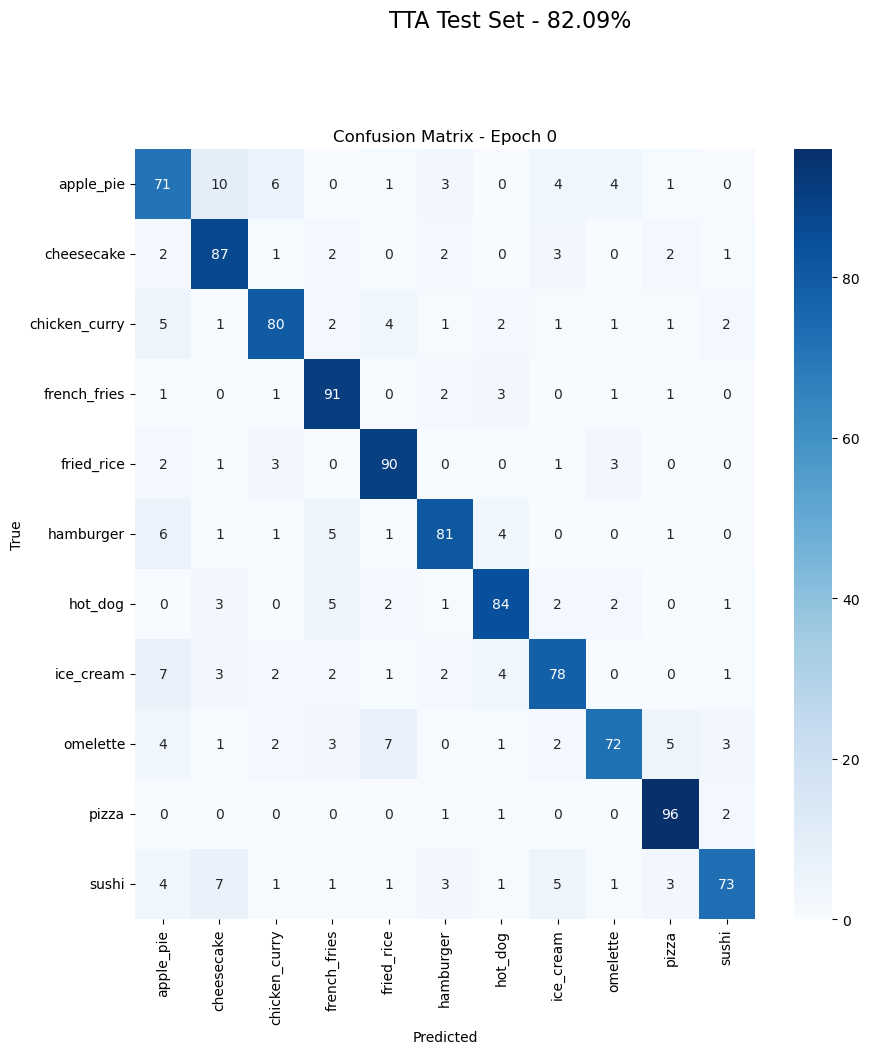

In [18]:
cm_tta = confusion_matrix(test_labels, test_preds)
cm_fig = plot_confusion_matrix(cm_tta, class_names, epoch=-1)
cm_fig.suptitle(f"TTA Test Set - {test_acc:.2f}%", fontsize=16, y=1.02)
cm_fig.savefig("FINAL_confusion_matrix_TTA.png", dpi=200, bbox_inches='tight')
plt.show()

In [20]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, WeightedRandomSampler
from torchvision import datasets, transforms, models
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from torch.utils.data import Subset
from collections import Counter

data_dir = "food11"
train_dir = os.path.join(data_dir, "train")
test_dir = os.path.join(data_dir, "test")

batch_size = 32
num_epochs = 50  # Увеличили — будем дообучать глубже
learning_rate_classifier = 1e-3
learning_rate_features = 1e-5  # Меньше для размороженных слоёв

patience = 7  # Больше терпения при fine-tuning
best_acc = -float("inf")
patience_counter = 0

torch.manual_seed(42)
device = ("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

full_train_augmented = datasets.ImageFolder(train_dir, transform=train_transform, is_valid_file=valid_image)
full_train_clean = datasets.ImageFolder(train_dir, transform=val_test_transform, is_valid_file=valid_image)
test_dataset = datasets.ImageFolder(test_dir, transform=val_test_transform, is_valid_file=valid_image)
if full_train_augmented.class_to_idx != test_dataset.class_to_idx:
    raise ValueError("Train and test folders must contain the same classes.")

# Split на train/val (80/20)
train_size = int(0.8 * len(full_train_augmented))
val_size = len(full_train_augmented) - train_size

indices = list(range(len(full_train_augmented)))
np.random.seed(42)
np.random.shuffle(indices)
train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = Subset(full_train_augmented, train_indices)
val_dataset = Subset(full_train_clean, val_indices)

num_classes = len(full_train_augmented.classes)
class_names = full_train_augmented.classes
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")
print(f"Классы ({num_classes}): {class_names}")

train_labels = [label for _, label in train_dataset]
class_counts = Counter(train_labels)
print("Распределение классов в train:", class_counts)

# Вычисляем веса для каждого класса
class_weights = [len(train_labels) / (num_classes * class_counts[i]) for i in range(num_classes)]
sample_weights = [class_weights[label] for label in train_labels]

# WeightedRandomSampler
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=batch_size, sampler=sampler, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

model = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, num_classes)

# Разморозка последних блоков
for name, param in model.named_parameters():
    if "features.7" in name or "features.8" in name or "classifier" in name:
        param.requires_grad = True
    else:
        param.requires_grad = False

model = model.to(device)

# Оптимизатор
optimizer = optim.Adam([
    {'params': model.features.parameters(), 'lr': 5e-6},
    {'params': model.classifier.parameters(), 'lr': 5e-4}
])

# Loss
criterion = nn.CrossEntropyLoss(label_smoothing=0.1, weight=torch.tensor(class_weights).to(device))

# Scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)

writer = SummaryWriter(log_dir="runs/food11_efficientnet_B3")

def plot_confusion_matrix(cm, class_names, epoch):
    fig, ax = plt.subplots(figsize=(10, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Confusion Matrix - Epoch {epoch+1}')
    return fig

def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = running_loss / len(loader)
    accuracy = 100.0 * np.mean(np.array(all_preds) == np.array(all_labels))
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    cm = confusion_matrix(all_labels, all_preds)

    return avg_loss, accuracy, precision, recall, f1, all_preds, all_labels, cm

start_time = time.time()
print("\nОбучение (fine-tuning + label smoothing + weighted sampling)")

for epoch in range(num_epochs):
    epoch_start = time.time()
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]", leave=False, ncols=100)

    for images, labels in train_pbar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

        train_pbar.set_postfix({'loss': f'{loss.item():.3f}'})

    avg_train_loss = running_loss / len(train_loader)
    train_acc = 100. * correct / total

    # Валидация
    val_loss, val_acc, val_prec, val_rec, val_f1, val_preds, val_labels, val_cm = evaluate_model(model, val_loader, criterion, device)

    # Логи
    writer.add_scalar("Loss/Train", avg_train_loss, epoch)
    writer.add_scalar("Loss/Validation", val_loss, epoch)
    writer.add_scalar("Accuracy/Train", train_acc, epoch)
    writer.add_scalar("Accuracy/Validation", val_acc, epoch)
    writer.add_scalar("Precision/Validation", val_prec, epoch)
    writer.add_scalar("Recall/Validation", val_rec, epoch)
    writer.add_scalar("F1/Validation", val_f1, epoch)
    writer.add_scalar("Learning_Rate_Classifier", optimizer.param_groups[1]['lr'], epoch)
    writer.add_scalar("Learning_Rate_Features", optimizer.param_groups[0]['lr'], epoch)

    if (epoch + 1) % 5 == 0:
        cm_fig = plot_confusion_matrix(val_cm, class_names, epoch)
        writer.add_figure("Confusion_Matrix/Validation", cm_fig, epoch)
        plt.close(cm_fig)

    scheduler.step(val_acc)

    epoch_time = time.time() - epoch_start
    elapsed = time.time() - start_time
    est_remaining = (elapsed / (epoch + 1)) * (num_epochs - (epoch + 1))

    print(f"Epoch {epoch+1:02d}/{num_epochs} | "
          f"Train: L={avg_train_loss:.3f} A={train_acc:.1f}% | "
          f"Val: L={val_loss:.3f} A={val_acc:.1f}% | "
          f"LR_c={optimizer.param_groups[1]['lr']:.2e} LR_f={optimizer.param_groups[0]['lr']:.2e} | "
          f"Time: {epoch_time:.0f}s | ETA: {est_remaining/60:.1f}min")

    # Early stopping
    if val_acc > best_acc:
        best_acc = val_acc
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_acc': best_acc,
            'class_names': class_names
        }, "efficientnet_B3_food11.pth")
        print(f"Лучшая модель сохранена! Val Acc: {best_acc:.2f}%")
    else:
        patience_counter += 1
        print(f"Нет улучшения {patience_counter}/{patience} эпох")
        if patience_counter >= patience:
            print(f"\nОстановка на эпохе {epoch+1}")
            print(f"Лучший результат: {best_acc:.2f}%")
            break


print("Финальная оценка на Test Set...")
checkpoint = torch.load("efficientnet_B3_food11.pth", map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])

test_loss, test_acc, test_prec, test_rec, test_f1, test_preds, test_labels, test_cm = evaluate_model(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.3f} | Accuracy: {test_acc:.2f}% | Precision: {test_prec:.3f} | Recall: {test_rec:.3f} | F1: {test_f1:.3f}")

# Сохраняем матрицу
cm_fig = plot_confusion_matrix(test_cm, class_names, -1)
cm_fig.savefig("confusion_matrix_test_В3.png")
plt.close(cm_fig)
print("Confusion matrix сохранена: confusion_matrix_test_B3.png")

total_time = time.time() - start_time
print(f"Общее время: {total_time/60:.1f} минут")
print(f"Лучшая Val Accuracy: {best_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Модель сохранена: efficientnet_B3_food11.pth")

writer.close()

Устройство: mps
Train: 7920 | Val: 1980 | Test: 1100
Классы (11): ['apple_pie', 'cheesecake', 'chicken_curry', 'french_fries', 'fried_rice', 'hamburger', 'hot_dog', 'ice_cream', 'omelette', 'pizza', 'sushi']
Распределение классов в train: Counter({2: 735, 6: 729, 5: 728, 0: 727, 10: 721, 9: 720, 4: 717, 8: 716, 1: 712, 7: 708, 3: 707})


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to ~/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth
100.0%
/opt/miniconda3/envs/torch_ml/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(



Обучение (fine-tuning + label smoothing + weighted sampling)


Epoch 01/50 | Train: L=1.865 A=51.8% | Val: L=1.413 A=71.8% | LR_c=5.00e-04 LR_f=5.00e-06 | Time: 232s | ETA: 189.7min
Лучшая модель сохранена! Val Acc: 71.77%


Epoch 02/50 | Train: L=1.431 A=65.2% | Val: L=1.211 A=75.7% | LR_c=5.00e-04 LR_f=5.00e-06 | Time: 236s | ETA: 187.6min
Лучшая модель сохранена! Val Acc: 75.71%


Epoch 03/50 | Train: L=1.300 A=69.4% | Val: L=1.135 A=77.7% | LR_c=5.00e-04 LR_f=5.00e-06 | Time: 307s | ETA: 202.8min
Лучшая модель сохранена! Val Acc: 77.73%


... (21 outputs left out)

Epoch 25/50 | Train: L=1.092 A=77.7% | Val: L=0.994 A=83.6% | LR_c=5.00e-04 LR_f=5.00e-06 | Time: 381s | ETA: 103.9min
Нет улучшения 4/7 эпох


Epoch 26/50 | Train: L=1.076 A=78.8% | Val: L=0.983 A=84.3% | LR_c=2.50e-04 LR_f=2.50e-06 | Time: 258s | ETA: 99.9min
Нет улучшения 5/7 эпох


Epoch 27/50 | Train: L=1.059 A=79.3% | Val: L=0.980 A=84.1% | LR_c=2.50e-04 LR_f=2.50e-06 | Time: 318s | ETA: 96.7min
Нет улучшения 6/7 эпох


Epoch 28/50 | Train: L=1.070 A=79.3% | Val: L=0.990 A=83.6% | LR_c=2.50e-04 LR_f=2.50e-06 | Time: 361s | ETA: 93.9min
Нет улучшения 7/7 эпох

Остановка на эпохе 28
Лучший результат: 84.34%
Финальная оценка на Test Set...
Test Loss: 1.001 | Accuracy: 82.00% | Precision: 0.821 | Recall: 0.820 | F1: 0.820
Confusion matrix сохранена: confusion_matrix_test_B3.png
Общее время: 119.9 минут
Лучшая Val Accuracy: 84.34%
Test Accuracy: 82.00%
Модель сохранена: efficientnet_B3_food11.pth


In [22]:
# Замени финальную оценку:
test_preds = tta_predict(model, test_loader, device)
test_labels = [label for _, label in test_loader.dataset]
test_acc = 100.0 * np.mean(np.array(test_preds) == np.array(test_labels))
print(f"TTA Test Accuracy: {test_acc:.2f}%")

TTA Test Accuracy: 84.82%


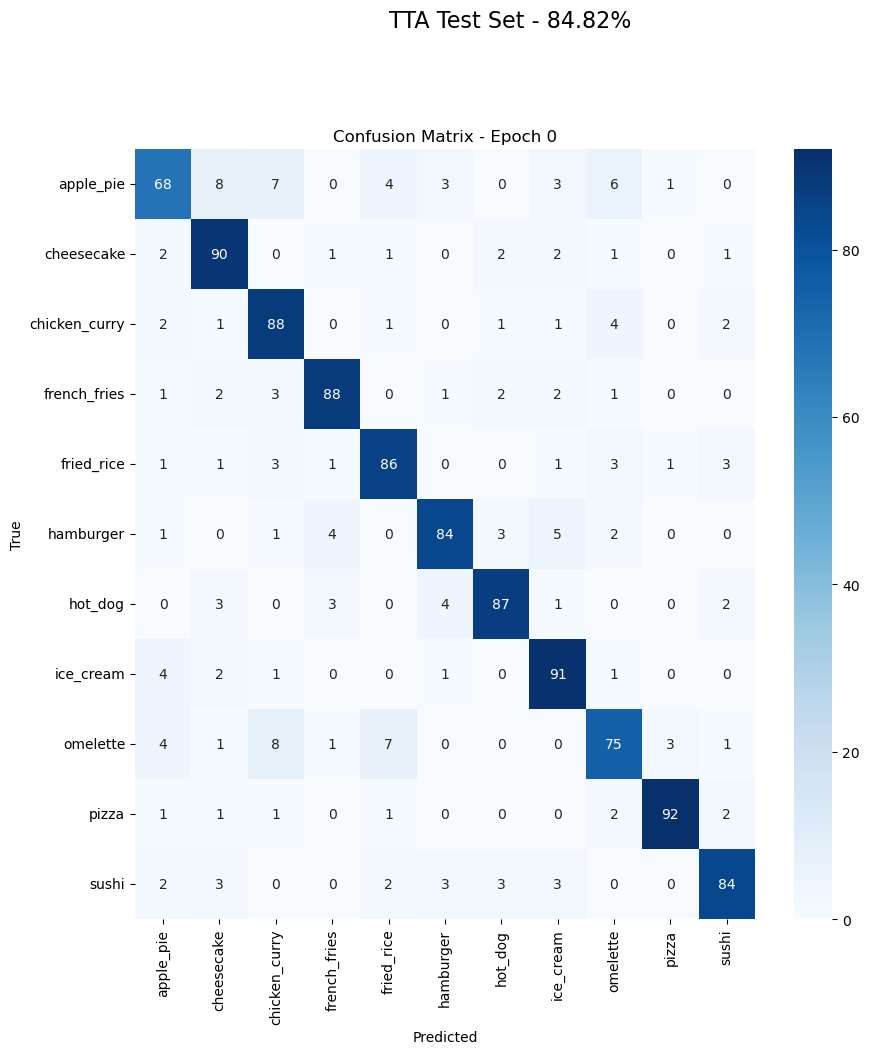

In [23]:
cm_tta = confusion_matrix(test_labels, test_preds)
cm_fig = plot_confusion_matrix(cm_tta, class_names, epoch=-1)
cm_fig.suptitle(f"TTA Test Set - {test_acc:.2f}%", fontsize=16, y=1.02)
cm_fig.savefig("FINAL_confusion_matrix_TTA.png", dpi=200, bbox_inches='tight')
plt.show()

In [26]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, WeightedRandomSampler
from torchvision import datasets, transforms, models
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from torch.utils.data import Subset
from collections import Counter

data_dir = "food11"
train_dir = os.path.join(data_dir, "train")
test_dir = os.path.join(data_dir, "test")

batch_size = 32
num_epochs = 50  # Увеличили — будем дообучать глубже
learning_rate_classifier = 1e-3
learning_rate_features = 1e-6  # Меньше для размороженных слоёв

patience = 7  # Больше терпения при fine-tuning
best_acc = -float("inf")
patience_counter = 0

torch.manual_seed(42)
device = ("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

full_train_augmented = datasets.ImageFolder(train_dir, transform=train_transform, is_valid_file=valid_image)
full_train_clean = datasets.ImageFolder(train_dir, transform=val_test_transform, is_valid_file=valid_image)
test_dataset = datasets.ImageFolder(test_dir, transform=val_test_transform, is_valid_file=valid_image)
if full_train_augmented.class_to_idx != test_dataset.class_to_idx:
    raise ValueError("Train and test folders must contain the same classes.")

# Split на train/val (80/20)
train_size = int(0.8 * len(full_train_augmented))
val_size = len(full_train_augmented) - train_size

indices = list(range(len(full_train_augmented)))
np.random.seed(42)
np.random.shuffle(indices)
train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = Subset(full_train_augmented, train_indices)
val_dataset = Subset(full_train_clean, val_indices)

num_classes = len(full_train_augmented.classes)
class_names = full_train_augmented.classes
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")
print(f"Классы ({num_classes}): {class_names}")

train_labels = [label for _, label in train_dataset]
class_counts = Counter(train_labels)
print("Распределение классов в train:", class_counts)

# Вычисляем веса для каждого класса
class_weights = [len(train_labels) / (num_classes * class_counts[i]) for i in range(num_classes)]
sample_weights = [class_weights[label] for label in train_labels]

# WeightedRandomSampler
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=batch_size, sampler=sampler, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

model = models.efficientnet_b5(weights=models.EfficientNet_B5_Weights.IMAGENET1K_V1)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, num_classes)

for name, param in model.named_parameters():
    if "features.6" in name or "features.7" in name or "features.8" in name or "classifier" in name:
        param.requires_grad = True
    else:
        param.requires_grad = False

# Проверка
print("Обучаемые параметры:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"  [Train] {name}")

model = model.to(device)

optimizer = optim.AdamW([
    {'params': [p for n, p in model.named_parameters() if "features.7" in n or "features.8" in n], 'lr': 1e-6},
    {'params': model.classifier.parameters(), 'lr': 3e-4}
], weight_decay=1e-4)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1, weight=torch.tensor(class_weights).to(device))

scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2, eta_min=1e-7)

writer = SummaryWriter(log_dir="runs/food11_efficientnet_B5")

def plot_confusion_matrix(cm, class_names, epoch):
    fig, ax = plt.subplots(figsize=(10, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Confusion Matrix - Epoch {epoch+1}')
    return fig

def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = running_loss / len(loader)
    accuracy = 100.0 * np.mean(np.array(all_preds) == np.array(all_labels))
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    cm = confusion_matrix(all_labels, all_preds)

    return avg_loss, accuracy, precision, recall, f1, all_preds, all_labels, cm

start_time = time.time()
print("\nОбучение (fine-tuning + label smoothing + weighted sampling)")

for epoch in range(num_epochs):
    epoch_start = time.time()
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]", leave=False, ncols=100)

    for images, labels in train_pbar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item()
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

        train_pbar.set_postfix({'loss': f'{loss.item():.3f}'})

    avg_train_loss = running_loss / len(train_loader)
    train_acc = 100. * correct / total

    # Валидация
    val_loss, val_acc, val_prec, val_rec, val_f1, val_preds, val_labels, val_cm = evaluate_model(model, val_loader, criterion, device)

    # Логи
    writer.add_scalar("Loss/Train", avg_train_loss, epoch)
    writer.add_scalar("Loss/Validation", val_loss, epoch)
    writer.add_scalar("Accuracy/Train", train_acc, epoch)
    writer.add_scalar("Accuracy/Validation", val_acc, epoch)
    writer.add_scalar("Precision/Validation", val_prec, epoch)
    writer.add_scalar("Recall/Validation", val_rec, epoch)
    writer.add_scalar("F1/Validation", val_f1, epoch)
    writer.add_scalar("Learning_Rate_Classifier", optimizer.param_groups[1]['lr'], epoch)
    writer.add_scalar("Learning_Rate_Features", optimizer.param_groups[0]['lr'], epoch)

    if (epoch + 1) % 5 == 0:
        cm_fig = plot_confusion_matrix(val_cm, class_names, epoch)
        writer.add_figure("Confusion_Matrix/Validation", cm_fig, epoch)
        plt.close(cm_fig)

    scheduler.step(val_acc)

    epoch_time = time.time() - epoch_start
    elapsed = time.time() - start_time
    est_remaining = (elapsed / (epoch + 1)) * (num_epochs - (epoch + 1))

    print(f"Epoch {epoch+1:02d}/{num_epochs} | "
          f"Train: L={avg_train_loss:.3f} A={train_acc:.1f}% | "
          f"Val: L={val_loss:.3f} A={val_acc:.1f}% | "
          f"LR_c={optimizer.param_groups[1]['lr']:.2e} LR_f={optimizer.param_groups[0]['lr']:.2e} | "
          f"Time: {epoch_time:.0f}s | ETA: {est_remaining/60:.1f}min")

    # Early stopping
    if val_acc > best_acc:
        best_acc = val_acc
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_acc': best_acc,
            'class_names': class_names
        }, "efficientnet_B5_food11.pth")
        print(f"Лучшая модель сохранена! Val Acc: {best_acc:.2f}%")
    else:
        patience_counter += 1
        print(f"Нет улучшения {patience_counter}/{patience} эпох")
        if patience_counter >= patience:
            print(f"\nОстановка на эпохе {epoch+1}")
            print(f"Лучший результат: {best_acc:.2f}%")
            break


print("Финальная оценка на Test Set...")
checkpoint = torch.load("efficientnet_B5_food11.pth", map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])

test_loss, test_acc, test_prec, test_rec, test_f1, test_preds, test_labels, test_cm = evaluate_model(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.3f} | Accuracy: {test_acc:.2f}% | Precision: {test_prec:.3f} | Recall: {test_rec:.3f} | F1: {test_f1:.3f}")

# Сохраняем матрицу
cm_fig = plot_confusion_matrix(test_cm, class_names, -1)
cm_fig.savefig("confusion_matrix_test_В5.png")
plt.close(cm_fig)
print("Confusion matrix сохранена: confusion_matrix_test_B5.png")

total_time = time.time() - start_time
print(f"Общее время: {total_time/60:.1f} минут")
print(f"Лучшая Val Accuracy: {best_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Модель сохранена: efficientnet_B5_food11.pth")

writer.close()

Устройство: mps
Train: 7920 | Val: 1980 | Test: 1100
Классы (11): ['apple_pie', 'cheesecake', 'chicken_curry', 'french_fries', 'fried_rice', 'hamburger', 'hot_dog', 'ice_cream', 'omelette', 'pizza', 'sushi']
Распределение классов в train: Counter({2: 735, 6: 729, 5: 728, 0: 727, 10: 721, 9: 720, 4: 717, 8: 716, 1: 712, 7: 708, 3: 707})
Обучаемые параметры:
  [Train] features.6.0.block.0.0.weight
  [Train] features.6.0.block.0.1.weight
  [Train] features.6.0.block.0.1.bias
  [Train] features.6.0.block.1.0.weight
  [Train] features.6.0.block.1.1.weight
  [Train] features.6.0.block.1.1.bias
  [Train] features.6.0.block.2.fc1.weight
  [Train] features.6.0.block.2.fc1.bias
  [Train] features.6.0.block.2.fc2.weight
  [Train] features.6.0.block.2.fc2.bias
  [Train] features.6.0.block.3.0.weight
  [Train] features.6.0.block.3.1.weight
  [Train] features.6.0.block.3.1.bias
  [Train] features.6.1.block.0.0.weight
  [Train] features.6.1.block.0.1.weight
  [Train] features.6.1.block.0.1.bias
  [Tr

Epoch 01/50 | Train: L=2.130 A=39.8% | Val: L=1.832 A=64.2% | LR_c=1.54e-05 LR_f=1.46e-07 | Time: 1133s | ETA: 925.6min
Лучшая модель сохранена! Val Acc: 64.19%


In [ ]:
# Замени финальную оценку:
test_preds = tta_predict(model, test_loader, device)
test_labels = [label for _, label in test_loader.dataset]
test_acc = 100.0 * np.mean(np.array(test_preds) == np.array(test_labels))
print(f"TTA Test Accuracy: {test_acc:.2f}%")

In [ ]:
cm_tta = confusion_matrix(test_labels, test_preds)
cm_fig = plot_confusion_matrix(cm_tta, class_names, epoch=-1)
cm_fig.suptitle(f"TTA Test Set - {test_acc:.2f}%", fontsize=16, y=1.02)
cm_fig.savefig("FINAL_confusion_matrix_TTA.png", dpi=200, bbox_inches='tight')
plt.show()

## Evaluation of the saved EfficientNet-B0 checkpoint

This run uses the checkpoint from the earlier training session, not newly trained weights. Supply `food11/` and `best_efficientnet_B0_food11.pth` in this folder to reproduce it. The test set has also been used in earlier model comparisons, so treat this as an exploratory evaluation.

Test images: 1100
Original checkpoint accuracy: 76.18%
Original + horizontal flip accuracy: 78.73%


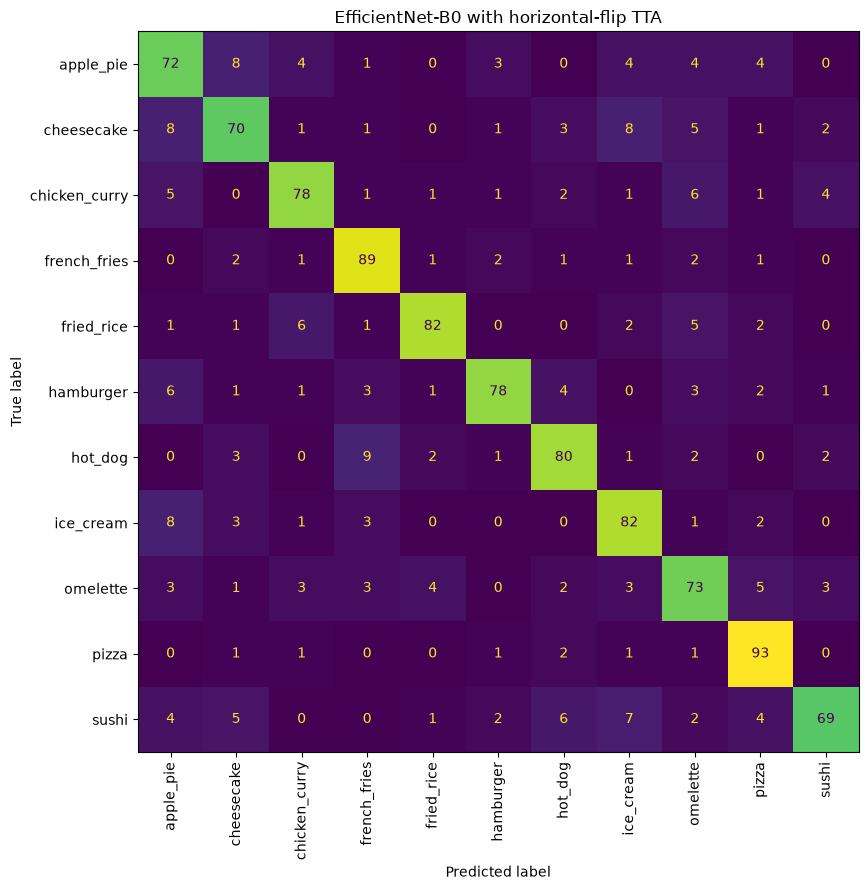

In [2]:
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

torch.set_num_threads(2)
root = Path('food11')
checkpoint_path = Path('best_efficientnet_B0_food11.pth')
# This checkpoint was created by the earlier training run. Load only trusted files.
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
test_data = datasets.ImageFolder(root / 'test', transform=transform, is_valid_file=valid_image)
if test_data.classes != checkpoint['class_names']:
    raise ValueError('The test class order does not match the checkpoint.')
loader = DataLoader(test_data, batch_size=32, shuffle=False, num_workers=0)
net = models.efficientnet_b0(weights=None)
net.classifier[1] = torch.nn.Linear(net.classifier[1].in_features, len(test_data.classes))
net.load_state_dict(checkpoint['model_state_dict'])
net.eval()
y_true, normal_preds, flip_preds = [], [], []
with torch.inference_mode():
    for images, labels in loader:
        original = torch.softmax(net(images), dim=1)
        flipped = torch.softmax(net(torch.flip(images, dims=[-1])), dim=1)
        normal_preds.extend(original.argmax(dim=1).tolist())
        flip_preds.extend((original + flipped).argmax(dim=1).tolist())
        y_true.extend(labels.tolist())
print(f'Test images: {len(y_true)}')
print(f'Original checkpoint accuracy: {accuracy_score(y_true, normal_preds):.2%}')
print(f'Original + horizontal flip accuracy: {accuracy_score(y_true, flip_preds):.2%}')
cm = confusion_matrix(y_true, flip_preds, labels=np.arange(len(test_data.classes)))
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(cm, display_labels=test_data.classes).plot(ax=ax, xticks_rotation=90, colorbar=False)
ax.set_title('EfficientNet-B0 with horizontal-flip TTA')
plt.tight_layout()
plt.show()
